In [20]:
import os
import pandas as pd
import numpy as np
from pyexpat import features
import neural_ode
from neural_ode import generate_synthetic_data, prep_data, prep_batches, create_model
from neural_ode import train_pretrain, train_fit_gmm, train_finetune, predict, evaluate_performance
from neural_ode import plot_input_trajectories, plot_predicted_trajectories, plot_latent_space, plot_training_loss


### Create dataset

In [21]:
train_data_df, test_data_df = generate_synthetic_data(
    n_train=300, n_test=100, n_classes=3, n_features=4,
    length=60, irregularity=0.5, noise=0.2, seed=42,
)


### Examine dataset

In [22]:
print(f"Rows: {len(train_data_df)}")
print(f"Trajectories: {train_data_df['trajectory_id'].nunique()}")
print(f"Labels: {train_data_df['label'].nunique()}")
print(f"Features: {[c for c in train_data_df.columns if c.startswith('feature_')]}")
print(f"Rows per trajectory:\n{train_data_df.groupby('trajectory_id').size().describe().round(1)}")

Rows: 18000
Trajectories: 300
Labels: 3
Features: ['feature_0', 'feature_1', 'feature_2', 'feature_3']
Rows per trajectory:
count    300.0
mean      60.0
std        0.0
min       60.0
25%       60.0
50%       60.0
75%       60.0
max       60.0
dtype: float64


### Prep Dataset

In [23]:
[c for c in train_data_df.columns if c.startswith('feature_')]

['feature_0', 'feature_1', 'feature_2', 'feature_3']

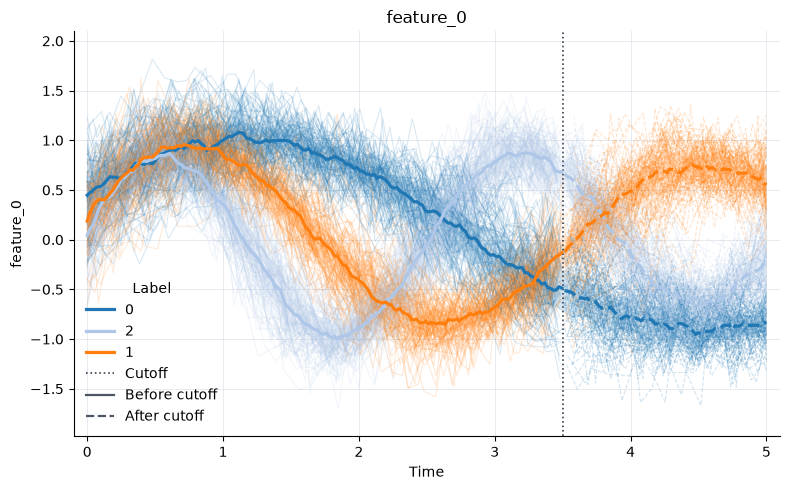

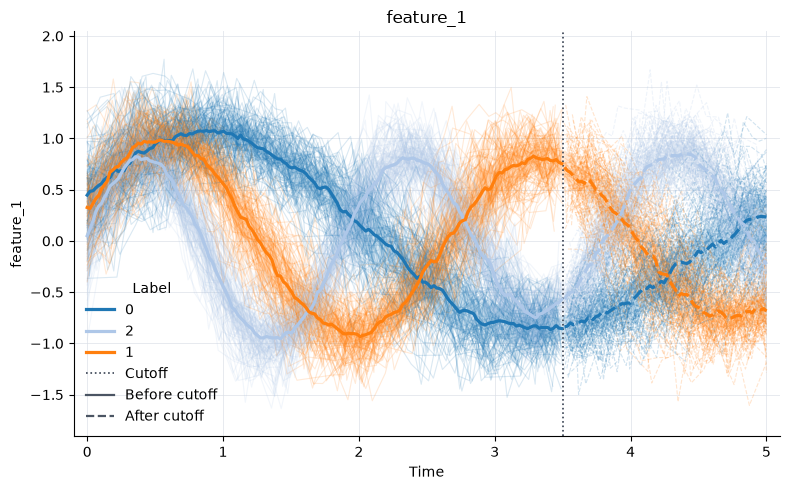

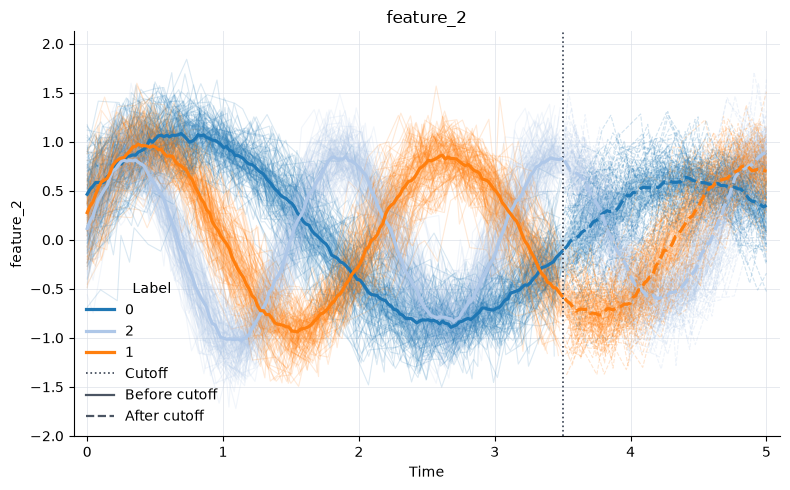

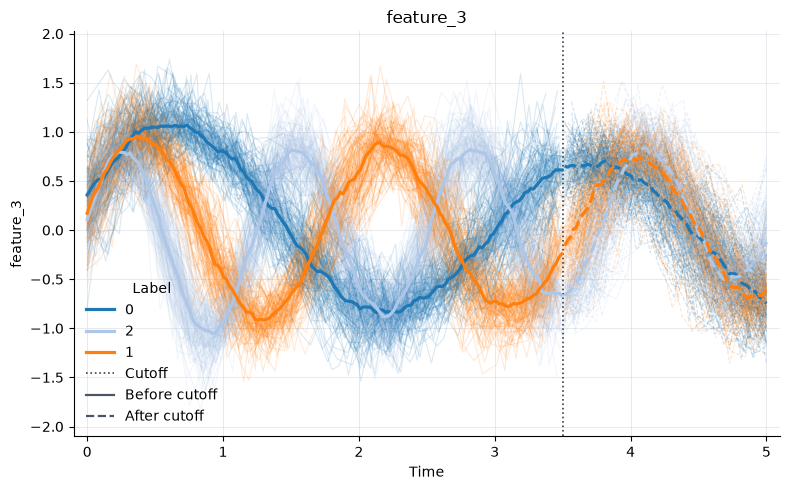

In [24]:
data = prep_data(
    train_data_df, id_col="trajectory_id", 
    time_col="time",
    feature_cols= [c for c in train_data_df.columns if c.startswith('feature_')], 
    label_col="label",
    cutoff=3.5, 
    cutoff_mode="time",
)

plot_input_trajectories(data)

loader = prep_batches(data, batch_size=16, val_split=0.2, normalize=True)


In [25]:
model = create_model(len(data.feature_names), {
    "model_name": "LatentODE_odernn",
    "latent_dim": 8,
    "k": 3,
    "method": "euler",
    "networks": {
        "z0_encoder_odernn": {
            "state_dim": 64,
            "recognition_ode_hidden_dims": [32],
            "gru_update_hidden_dims": [64],
            "posterior_hidden_dims": [32],
        },
        "generative_ode": {"hidden_dims": [32]},
        "emission": {"hidden_dims": [16]},
    },
})



pretrain epoch 1/200 | train_loss=1.33233 | val_loss=1.31074
pretrain epoch 2/200 | train_loss=1.29632 | val_loss=1.29527
pretrain epoch 3/200 | train_loss=1.28437 | val_loss=1.28517
pretrain epoch 4/200 | train_loss=1.26917 | val_loss=1.2727
pretrain epoch 5/200 | train_loss=1.25683 | val_loss=1.25317
pretrain epoch 6/200 | train_loss=1.23302 | val_loss=1.23187
pretrain epoch 7/200 | train_loss=1.20955 | val_loss=1.2066
pretrain epoch 8/200 | train_loss=1.18908 | val_loss=1.19296
pretrain epoch 9/200 | train_loss=1.16901 | val_loss=1.17228
pretrain epoch 10/200 | train_loss=1.15333 | val_loss=1.15657
pretrain epoch 11/200 | train_loss=1.13688 | val_loss=1.14225
pretrain epoch 12/200 | train_loss=1.11971 | val_loss=1.12347
pretrain epoch 13/200 | train_loss=1.10426 | val_loss=1.11616
pretrain epoch 14/200 | train_loss=1.08724 | val_loss=1.09535
pretrain epoch 15/200 | train_loss=1.07321 | val_loss=1.08448
pretrain epoch 16/200 | train_loss=1.06204 | val_loss=1.07434
pretrain epoch 17/2

{'feature_0': (<Figure size 800x500 with 1 Axes>,
  <Axes: title={'center': 'Predicted trajectories: feature_0'}, xlabel='Time', ylabel='feature_0'>),
 'feature_1': (<Figure size 800x500 with 1 Axes>,
  <Axes: title={'center': 'Predicted trajectories: feature_1'}, xlabel='Time', ylabel='feature_1'>),
 'feature_2': (<Figure size 800x500 with 1 Axes>,
  <Axes: title={'center': 'Predicted trajectories: feature_2'}, xlabel='Time', ylabel='feature_2'>),
 'feature_3': (<Figure size 800x500 with 1 Axes>,
  <Axes: title={'center': 'Predicted trajectories: feature_3'}, xlabel='Time', ylabel='feature_3'>)}

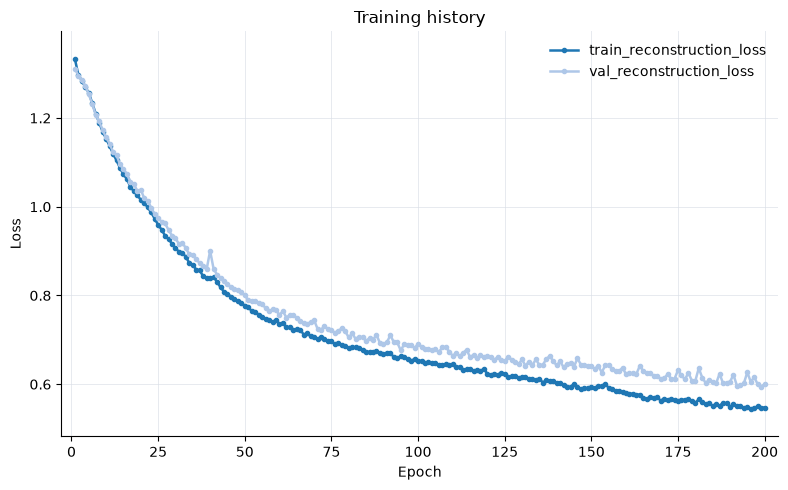

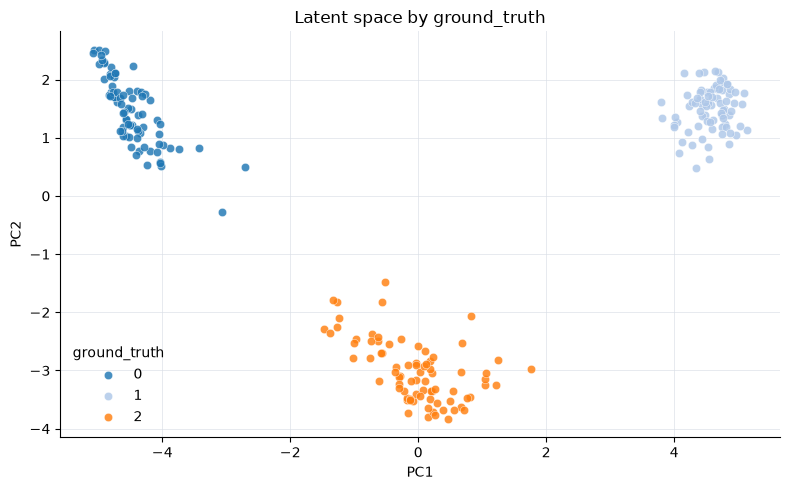

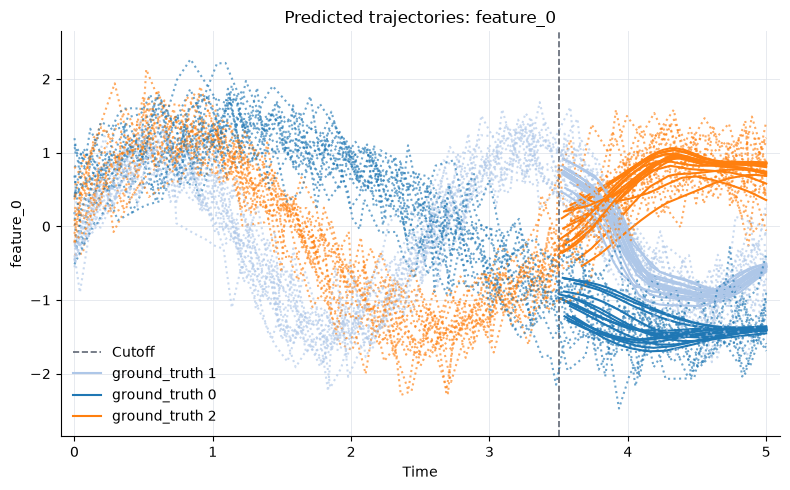

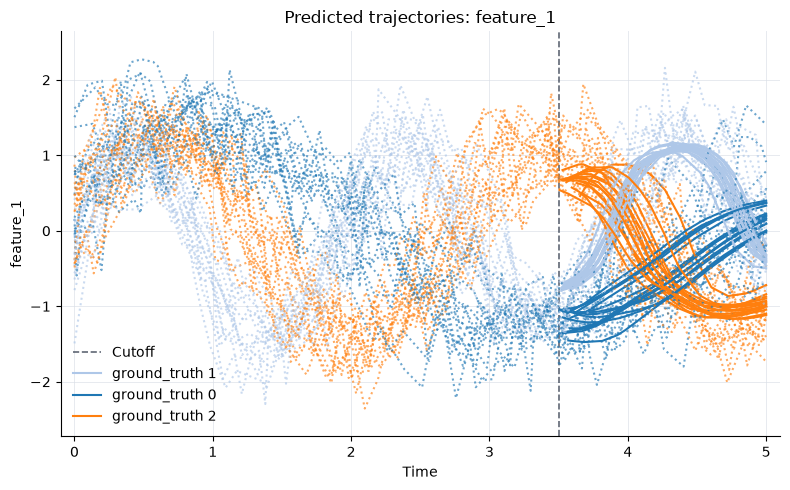

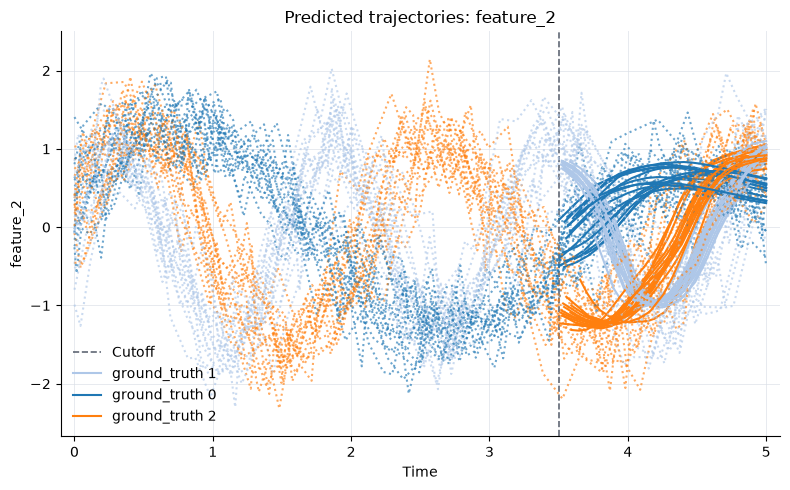

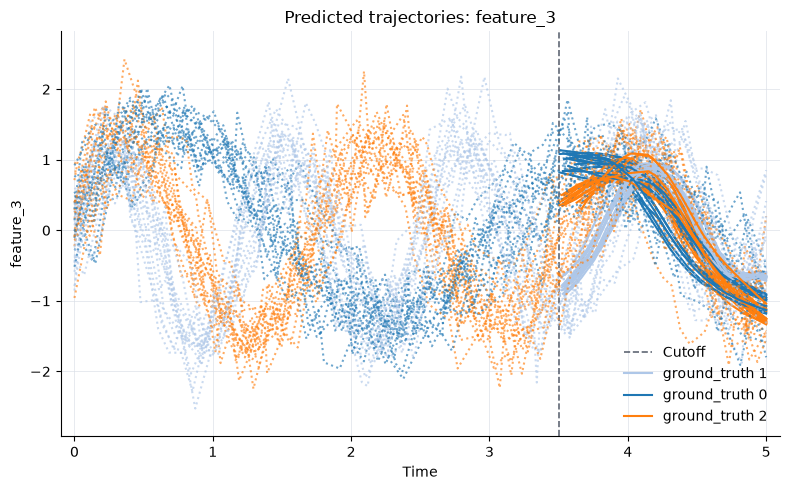

In [26]:
pretrain_result = train_pretrain(loader, model_config=model, epochs=200)

plot_training_loss(pretrain_result)
plot_latent_space(pretrain_result.model, loader, color_by="ground_truth")

predictions_pre = predict(pretrain_result.model, loader)
plot_predicted_trajectories(predictions_pre, max_trajectories_per_group=15, show_observed = True)

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Latent space by cluster'}, xlabel='PC1', ylabel='PC2'>,
 PCA(n_components=2))

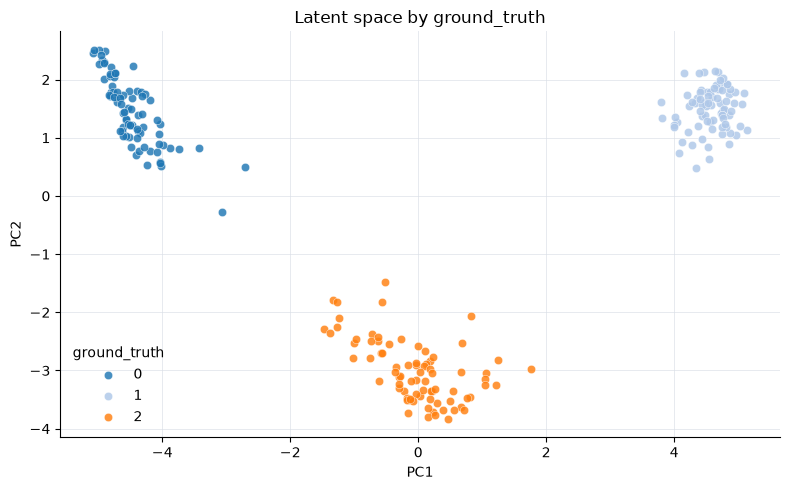

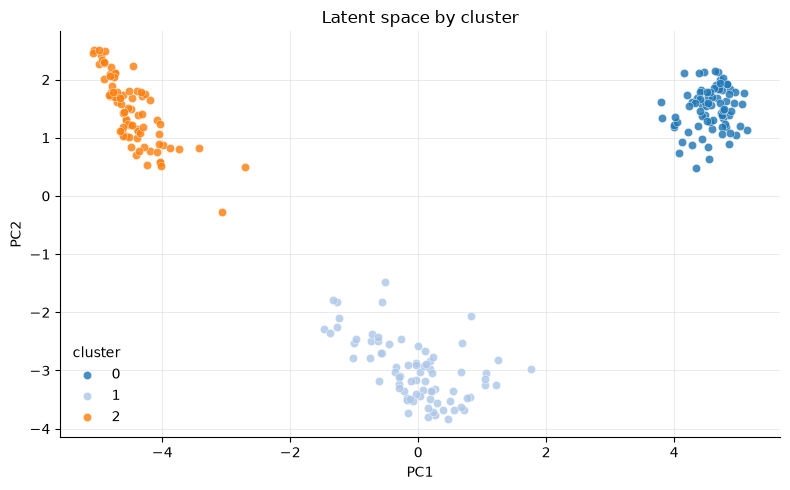

In [27]:
gmm_result = train_fit_gmm(pretrain_result.model, loader)

plot_latent_space(gmm_result.model, loader, color_by = "ground_truth")
plot_latent_space(gmm_result.model, loader, color_by = "cluster")

finetune epoch 1/50 | train_loss=0.721929 | val_loss=0.723947
finetune epoch 2/50 | train_loss=0.668424 | val_loss=0.709694
finetune epoch 3/50 | train_loss=0.649688 | val_loss=0.691702
finetune epoch 4/50 | train_loss=0.647053 | val_loss=0.676389
finetune epoch 5/50 | train_loss=0.645765 | val_loss=0.688748
finetune epoch 6/50 | train_loss=0.638636 | val_loss=0.691708
finetune epoch 7/50 | train_loss=0.636721 | val_loss=0.675643
finetune epoch 8/50 | train_loss=0.636809 | val_loss=0.672477
finetune epoch 9/50 | train_loss=0.63331 | val_loss=0.668431
finetune epoch 10/50 | train_loss=0.63121 | val_loss=0.680055
finetune epoch 11/50 | train_loss=0.630438 | val_loss=0.684714
finetune epoch 12/50 | train_loss=0.634394 | val_loss=0.683282
finetune epoch 13/50 | train_loss=0.631847 | val_loss=0.676145
finetune epoch 14/50 | train_loss=0.633035 | val_loss=0.682591
finetune epoch 15/50 | train_loss=0.625322 | val_loss=0.67515
finetune epoch 16/50 | train_loss=0.629331 | val_loss=0.679143
fine

{'feature_0': (<Figure size 800x500 with 1 Axes>,
  <Axes: title={'center': 'Predicted trajectories: feature_0'}, xlabel='Time', ylabel='feature_0'>),
 'feature_1': (<Figure size 800x500 with 1 Axes>,
  <Axes: title={'center': 'Predicted trajectories: feature_1'}, xlabel='Time', ylabel='feature_1'>),
 'feature_2': (<Figure size 800x500 with 1 Axes>,
  <Axes: title={'center': 'Predicted trajectories: feature_2'}, xlabel='Time', ylabel='feature_2'>),
 'feature_3': (<Figure size 800x500 with 1 Axes>,
  <Axes: title={'center': 'Predicted trajectories: feature_3'}, xlabel='Time', ylabel='feature_3'>)}

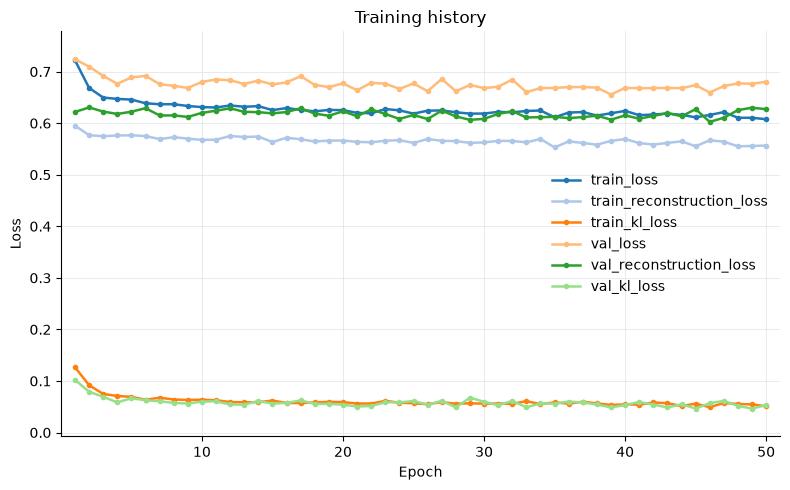

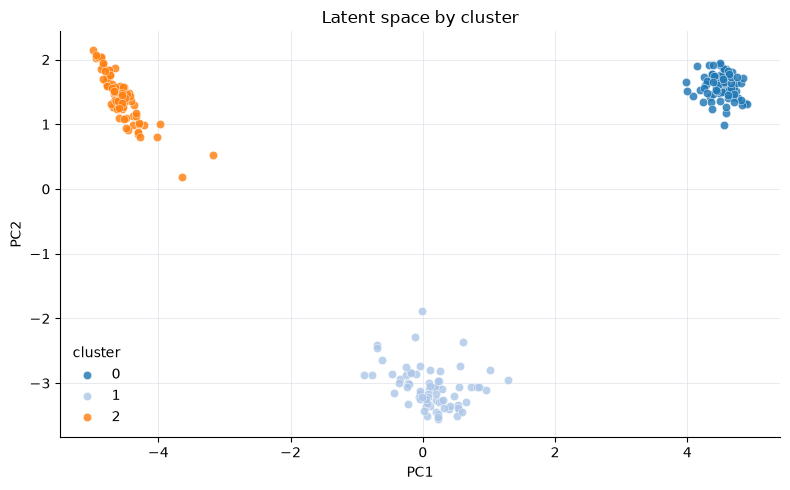

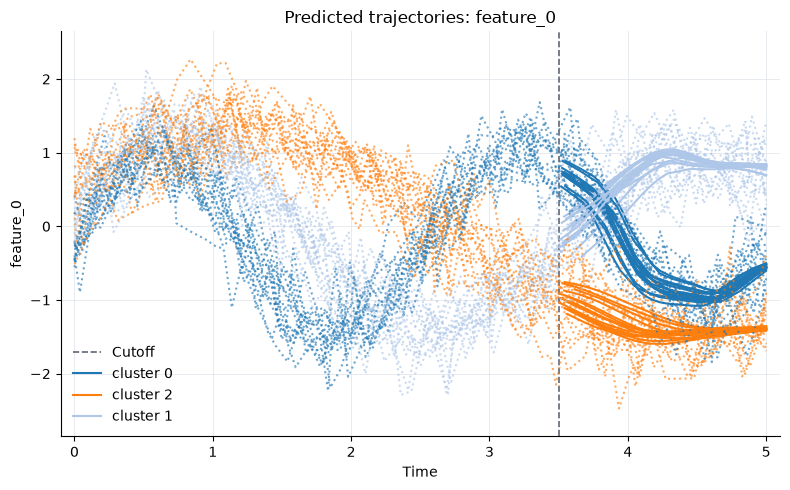

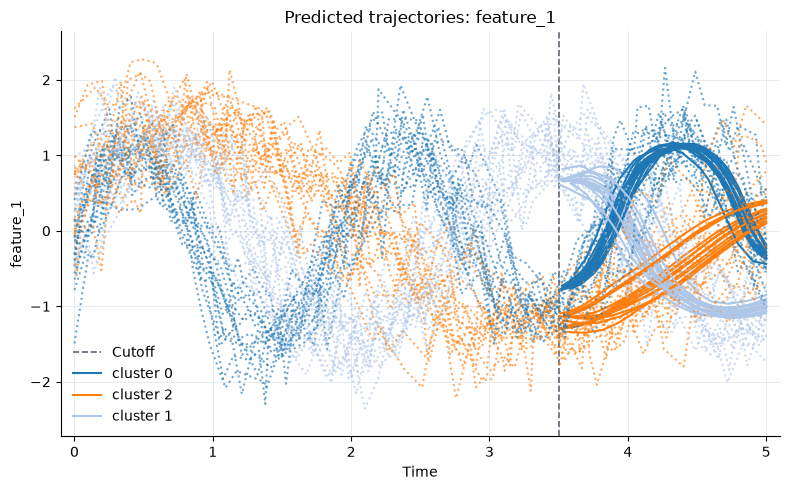

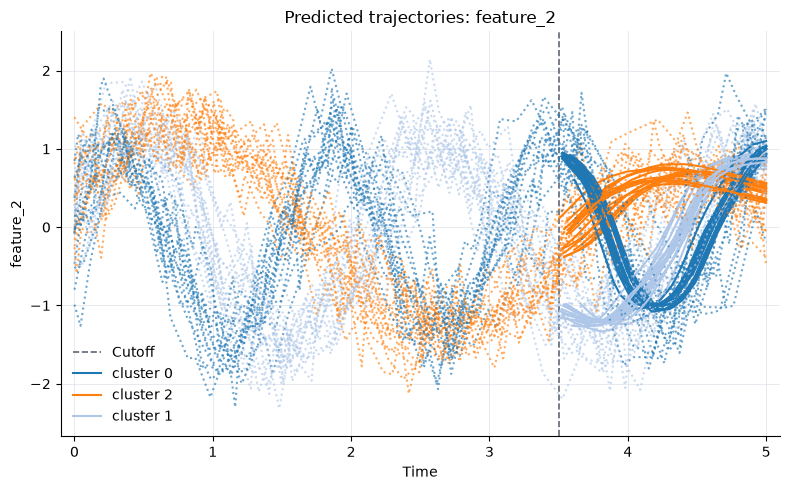

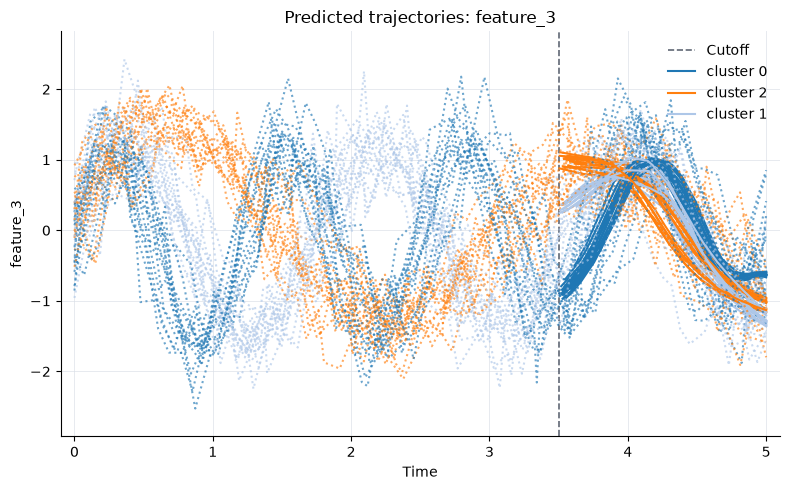

In [28]:
finetune_result = train_finetune(gmm_result.model, loader, epochs=50)

plot_training_loss(finetune_result)
plot_latent_space(finetune_result.model, loader, color_by="cluster")

predictions = predict(finetune_result.model, loader)
plot_predicted_trajectories(predictions, max_trajectories_per_group=15, show_observed = True)

### Prep test data

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Latent space by cluster'}, xlabel='PC1', ylabel='PC2'>,
 PCA(n_components=2))

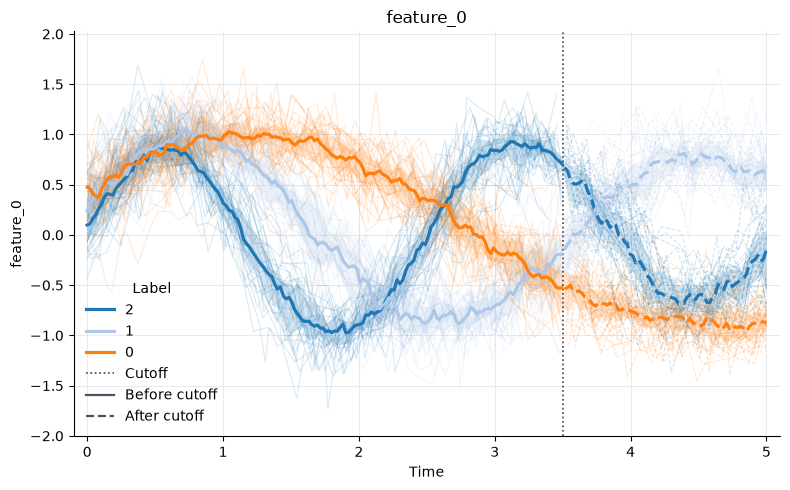

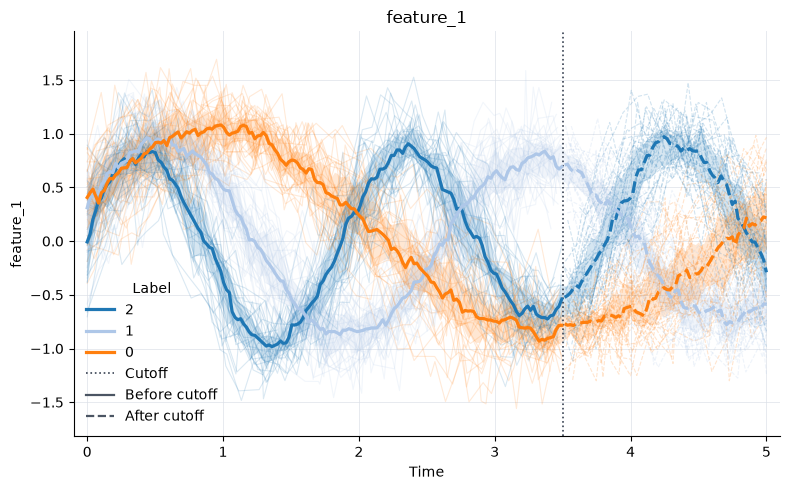

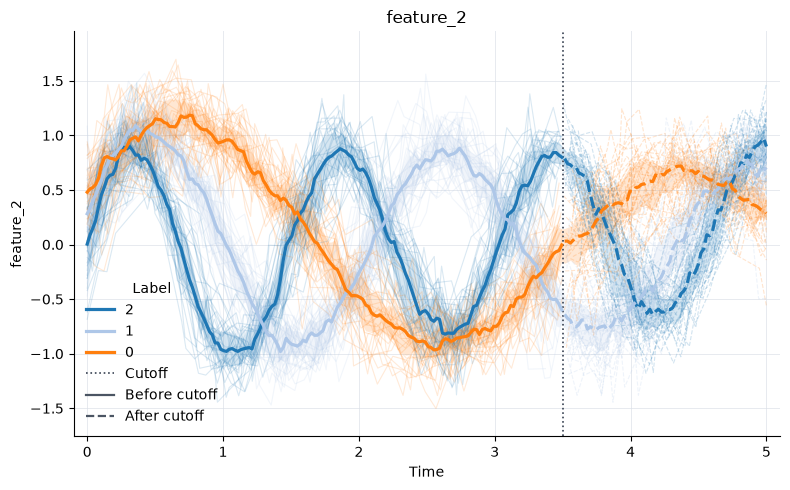

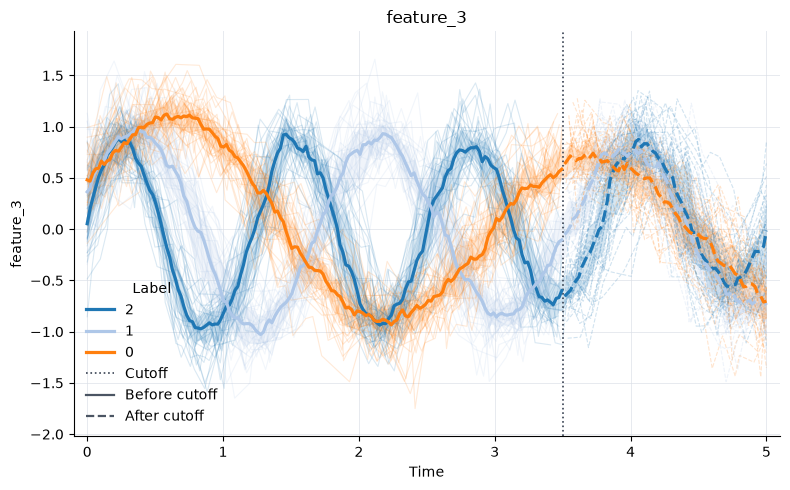

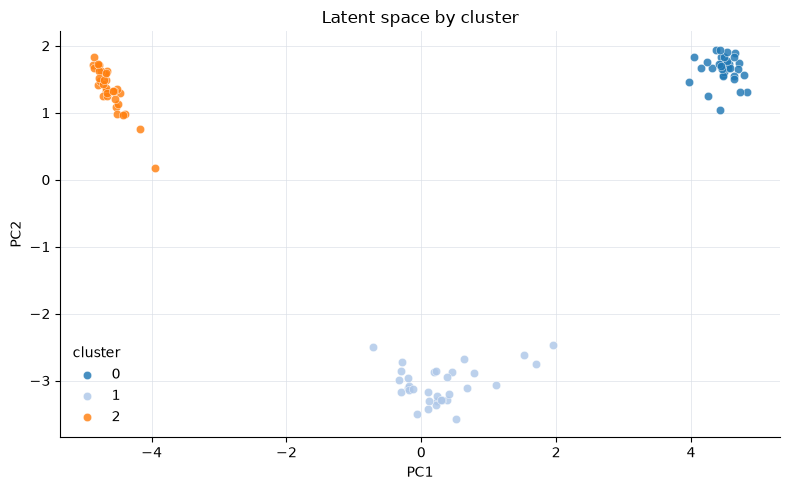

In [29]:
test_data = prep_data(
    test_data_df, id_col="trajectory_id", 
    time_col="time",
    feature_cols=[c for c in train_data_df.columns if c.startswith('feature_')], 
    label_col="label",
    cutoff=3.5, 
    cutoff_mode="time"
    )
plot_input_trajectories(test_data)
test_loader = prep_batches(test_data, batch_size=16, val_split=0, normalize=True)

plot_latent_space(finetune_result.model, test_loader, color_by="cluster")


{'mse': 0.19599608354693418,
 'nmi': 1.0,
 'ari': 1.0,
 'acc': 1.0,
 'silhouette': 0.880087673664093,
 'davies_bouldin': 0.17807865122824418,
 'calinski_harabasz': 2349.6494877197583}

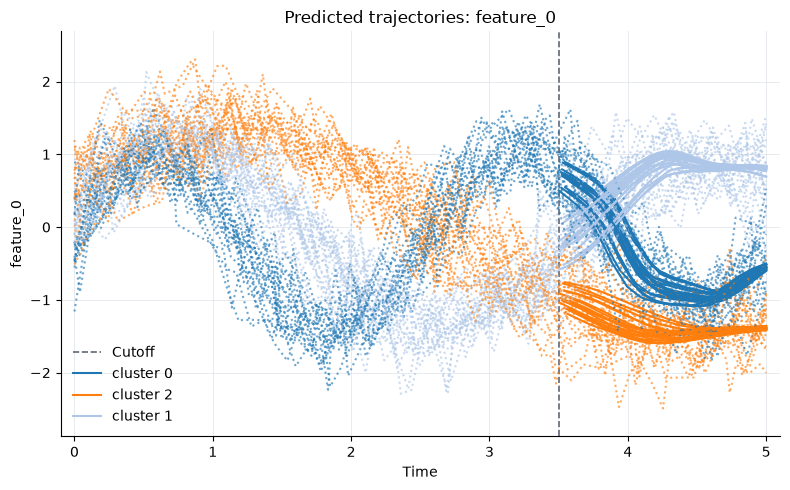

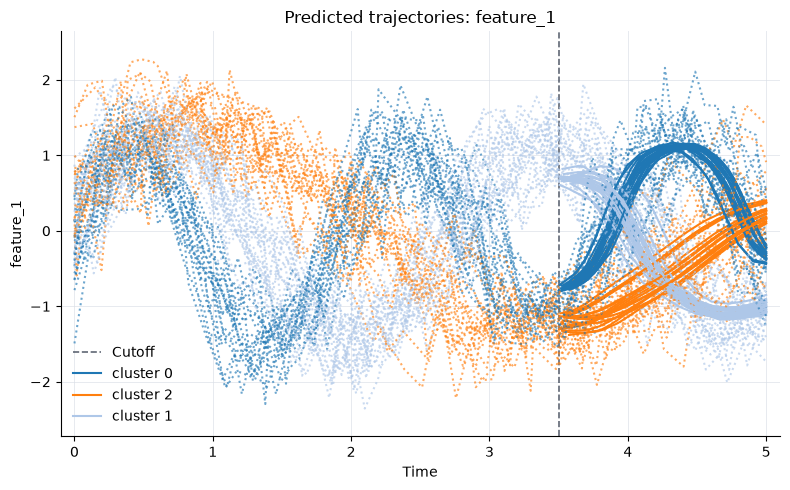

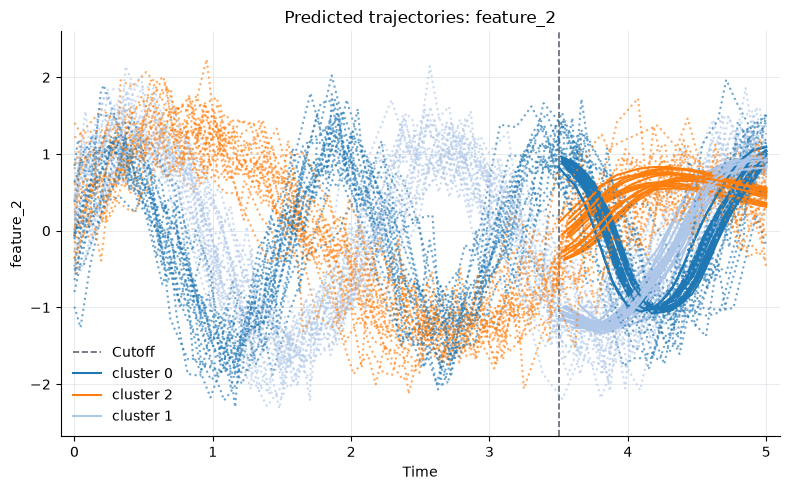

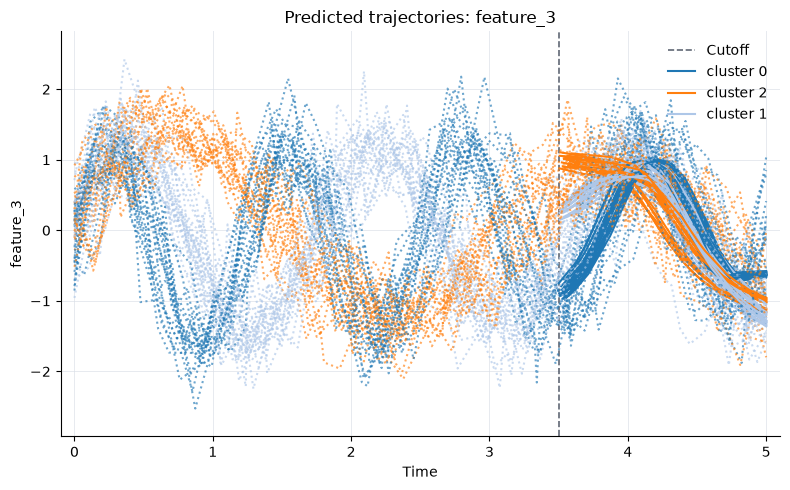

In [30]:

predictions = predict(finetune_result.model, loader)
plot_predicted_trajectories(predictions, max_trajectories_per_group=150, show_observed = True)

scores = evaluate_performance(finetune_result.model, test_loader.train)
scores